<a href="https://colab.research.google.com/github/ThePretelR/cassava-disease-model-comparison/blob/main/01_exploracion_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis exploratorio del dataset Cassava

Este notebook realiza el análisis exploratorio del dataset Cassava (TensorFlow Datasets, versión 0.1.0): exploración de clases, dimensiones y color de las imágenes, detección y limpieza de duplicados exactos (SHA-256) y perceptuales (pHash), construcción de los datasets definitivos y exportación de resultados.

## 1. Entorno y carga del dataset

In [1]:
import sys
import tensorflow as tf
import tensorflow_datasets as tfds

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPU disponibles:", gpus)

if gpus:
    print("GPU detectada correctamente")
else:
    print("No se detectó GPU")


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU detectada correctamente


In [2]:
%pip install importlib_resources

In [3]:

import importlib_resources

print("Biblioteca importlib_resources instalada correctamente")


Biblioteca importlib_resources instalada correctamente


In [4]:

# Nombre y versión del dataset
DATASET_NAME = "cassava"
DATASET_VERSION = "0.1.0"

# Descargar y cargar las particiones oficiales
(ds_train, ds_val, ds_test), ds_info = tfds.load(
    f"{DATASET_NAME}:{DATASET_VERSION}",
    split=["train", "validation", "test"],
    as_supervised=True,
    with_info=True,
    shuffle_files=False
)

print("Dataset cargado correctamente")
print("Nombre:", ds_info.name)
print("Versión:", ds_info.version)

print("\nCantidad de imágenes:")
print("Entrenamiento:", ds_info.splits["train"].num_examples)
print("Validación:", ds_info.splits["validation"].num_examples)
print("Prueba:", ds_info.splits["test"].num_examples)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.N8UY2F_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.N8UY2F_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.N8UY2F_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Dataset cargado correctamente
Nombre: cassava
Versión: 0.1.0

Cantidad de imágenes:
Entrenamiento: 5656
Validación: 1889
Prueba: 1885


## 2. Exploración de las clases

In [5]:
# Obtener los nombres de las clases
class_names = ds_info.features["label"].names

print("Número de clases:", len(class_names))
print("\nClases encontradas:")

for i, nombre in enumerate(class_names):
    print(f"{i}: {nombre}")

Número de clases: 5

Clases encontradas:
0: cbb
1: cbsd
2: cgm
3: cmd
4: healthy


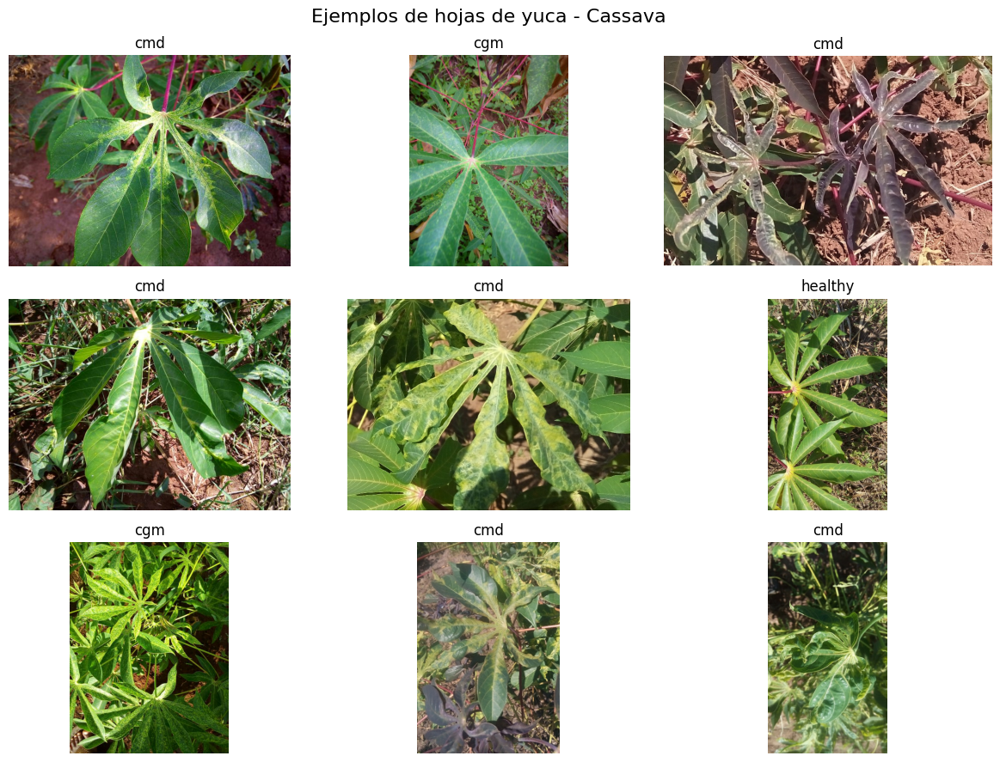

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 9))

# Mostrar las primeras 9 imágenes de entrenamiento
for i, (imagen, etiqueta) in enumerate(ds_train.take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(imagen.numpy())
    plt.title(class_names[int(etiqueta.numpy())])
    plt.axis("off")

plt.suptitle("Ejemplos de hojas de yuca - Cassava", fontsize=16)
plt.tight_layout()
plt.show()

Distribución de clases en entrenamiento:

cbb: 466 imágenes (8.24%)
cbsd: 1443 imágenes (25.51%)
cgm: 773 imágenes (13.67%)
cmd: 2658 imágenes (46.99%)
healthy: 316 imágenes (5.59%)


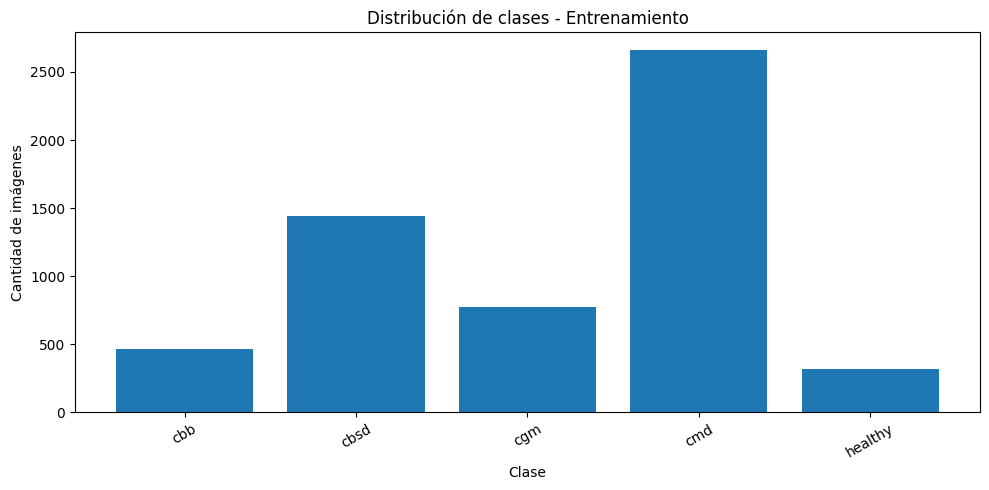

In [7]:

import numpy as np

# Contar las etiquetas del conjunto de entrenamiento
conteos = np.zeros(len(class_names), dtype=int)

for imagen, etiqueta in ds_train:
    conteos[int(etiqueta.numpy())] += 1

# Mostrar resultados
print("Distribución de clases en entrenamiento:\n")

for nombre, cantidad in zip(class_names, conteos):
    porcentaje = cantidad / sum(conteos) * 100
    print(f"{nombre}: {cantidad} imágenes ({porcentaje:.2f}%)")

# Crear gráfica
plt.figure(figsize=(10, 5))
plt.bar(class_names, conteos)

plt.title("Distribución de clases - Entrenamiento")
plt.xlabel("Clase")
plt.ylabel("Cantidad de imágenes")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 3. Análisis de dimensiones

In [8]:

from collections import Counter

# Obtener las dimensiones originales
dimensiones = []

for imagen, etiqueta in ds_train:
    alto, ancho, canales = imagen.shape
    dimensiones.append((int(alto), int(ancho)))

# Contar resoluciones
conteo_dimensiones = Counter(dimensiones)

print("Total de imágenes analizadas:", len(dimensiones))
print("Resoluciones diferentes:", len(conteo_dimensiones))

print("\nLas 10 resoluciones más frecuentes:")
for resolucion, cantidad in conteo_dimensiones.most_common(10):
    print(f"{resolucion}: {cantidad} imágenes")

# Estadísticas de tamaño
alturas = np.array([d[0] for d in dimensiones])
anchuras = np.array([d[1] for d in dimensiones])

print("\nAltura mínima:", alturas.min())
print("Altura máxima:", alturas.max())
print("Anchura mínima:", anchuras.min())
print("Anchura máxima:", anchuras.max())

Total de imágenes analizadas: 5656
Resoluciones diferentes: 574

Las 10 resoluciones más frecuentes:
(666, 500): 1442 imágenes
(500, 888): 781 imágenes
(500, 666): 657 imágenes
(500, 625): 635 imágenes
(500, 500): 435 imágenes
(888, 500): 312 imágenes
(500, 499): 29 imágenes
(500, 623): 12 imágenes
(500, 505): 10 imágenes
(500, 609): 9 imágenes

Altura mínima: 347
Altura máxima: 1240
Anchura mínima: 420
Anchura máxima: 1622


## 4. Visualización de imágenes por clase

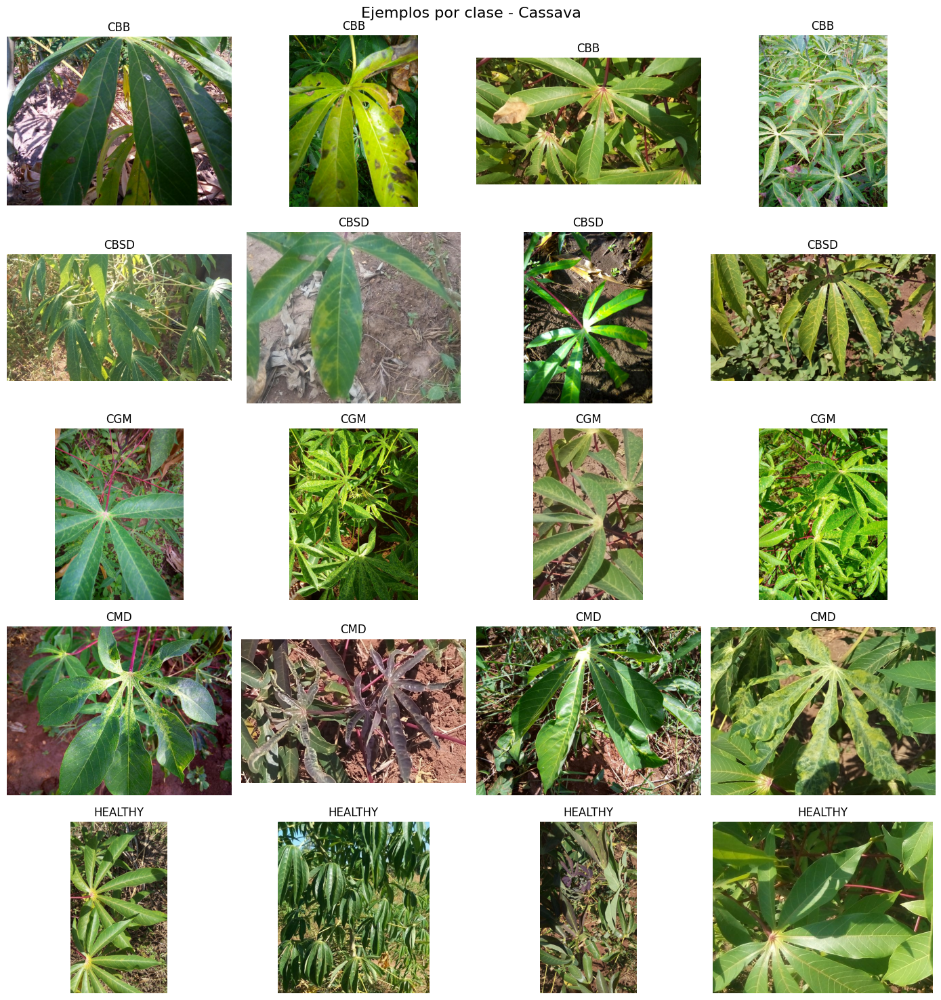

In [9]:

# Mostrar 4 imágenes de cada clase
ejemplos_por_clase = {i: [] for i in range(len(class_names))}

for imagen, etiqueta in ds_train:
    clase = int(etiqueta.numpy())

    if len(ejemplos_por_clase[clase]) < 4:
        ejemplos_por_clase[clase].append(imagen.numpy())

    if all(len(v) == 4 for v in ejemplos_por_clase.values()):
        break

fig, axes = plt.subplots(
    len(class_names), 4, figsize=(14, 15)
)

for i, nombre in enumerate(class_names):
    for j in range(4):
        axes[i, j].imshow(ejemplos_por_clase[i][j])
        axes[i, j].set_title(nombre.upper())
        axes[i, j].axis("off")

plt.suptitle("Ejemplos por clase - Cassava", fontsize=16)
plt.tight_layout()
plt.show()


## 5. Distribución de dimensiones y relaciones de aspecto

          alto    ancho  relacion_aspecto
count  5656.00  5656.00           5656.00
mean    572.88   610.93              1.12
std     109.93   140.61              0.38
min     347.00   420.00              0.40
25%     500.00   500.00              0.75
50%     500.00   534.00              1.07
75%     666.00   666.00              1.33
max    1240.00  1622.00              3.24


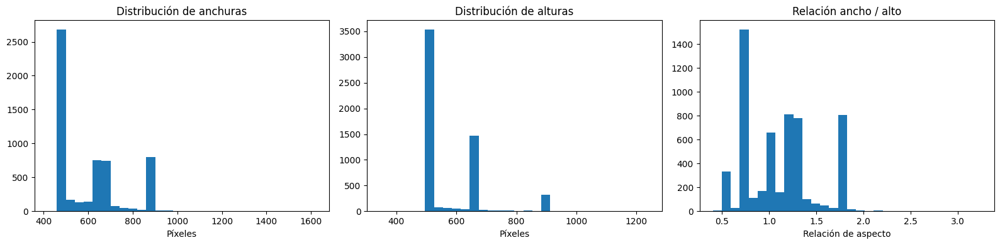

In [10]:

import pandas as pd

df_dimensiones = pd.DataFrame(
    dimensiones,
    columns=["alto", "ancho"]
)

df_dimensiones["relacion_aspecto"] = (
    df_dimensiones["ancho"] / df_dimensiones["alto"]
)

print(df_dimensiones.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df_dimensiones["ancho"], bins=30)
axes[0].set_title("Distribución de anchuras")
axes[0].set_xlabel("Píxeles")

axes[1].hist(df_dimensiones["alto"], bins=30)
axes[1].set_title("Distribución de alturas")
axes[1].set_xlabel("Píxeles")

axes[2].hist(
    df_dimensiones["relacion_aspecto"], bins=30
)
axes[2].set_title("Relación ancho / alto")
axes[2].set_xlabel("Relación de aspecto")

plt.tight_layout()
plt.show()


## 6. Estadísticas de brillo y canales RGB

In [11]:

from tqdm.auto import tqdm

estadisticas = []

for imagen, etiqueta in tqdm(
    ds_train, total=5656, desc="Analizando imágenes"
):
    img = imagen.numpy().astype(np.float32) / 255.0

    rgb = img.mean(axis=(0, 1))
    brillo = np.mean(
        0.299 * img[:, :, 0] +
        0.587 * img[:, :, 1] +
        0.114 * img[:, :, 2]
    )

    estadisticas.append({
        "clase": class_names[int(etiqueta.numpy())],
        "brillo": float(brillo),
        "rojo": float(rgb[0]),
        "verde": float(rgb[1]),
        "azul": float(rgb[2])
    })

df_estadisticas = pd.DataFrame(estadisticas)

print(
    df_estadisticas.groupby("clase")[
        ["brillo", "rojo", "verde", "azul"]
    ].agg(["mean", "std"]).round(3)
)

Analizando imágenes:   0%|          | 0/5656 [00:00<?, ?it/s]

        brillo          rojo         verde          azul       
          mean    std   mean    std   mean    std   mean    std
clase                                                          
cbb      0.463  0.067  0.442  0.077  0.507  0.073  0.297  0.110
cbsd     0.457  0.066  0.438  0.077  0.496  0.071  0.308  0.090
cgm      0.467  0.067  0.442  0.082  0.506  0.072  0.327  0.090
cmd      0.459  0.059  0.448  0.074  0.491  0.061  0.322  0.077
healthy  0.465  0.055  0.441  0.064  0.505  0.062  0.321  0.074


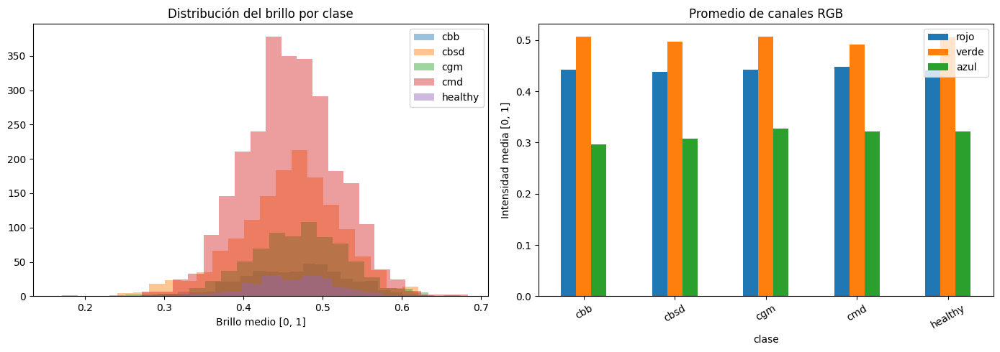

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for clase in class_names:
    valores = df_estadisticas.loc[
        df_estadisticas["clase"] == clase, "brillo"
    ]
    axes[0].hist(
        valores, bins=25, alpha=0.45, label=clase
    )

axes[0].set_title("Distribución del brillo por clase")
axes[0].set_xlabel("Brillo medio [0, 1]")
axes[0].legend()

promedios = df_estadisticas.groupby("clase")[
    ["rojo", "verde", "azul"]
].mean()

promedios.plot(kind="bar", ax=axes[1])
axes[1].set_title("Promedio de canales RGB")
axes[1].set_ylabel("Intensidad media [0, 1]")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 7. Detección y limpieza de duplicados SHA-256

In [13]:
import hashlib
from collections import defaultdict

def obtener_hash(imagen):
    img = imagen.numpy()
    h = hashlib.sha256()
    h.update(str(img.shape).encode("utf-8"))
    h.update(img.tobytes())
    return h.hexdigest()

def calcular_hashes(dataset, nombre):
    registros = []

    for i, (imagen, etiqueta) in enumerate(
        tqdm(dataset, desc=nombre)
    ):
        registros.append({
            "particion": nombre,
            "indice": i,
            "hash": obtener_hash(imagen),
            "clase": class_names[int(etiqueta.numpy())]
        })

    return pd.DataFrame(registros)

hash_train = calcular_hashes(ds_train, "train")
hash_val = calcular_hashes(ds_val, "validation")
hash_test = calcular_hashes(ds_test, "test")

df_hashes = pd.concat(
    [hash_train, hash_val, hash_test],
    ignore_index=True
)

print("Imágenes analizadas:", len(df_hashes))
print("Hashes únicos:", df_hashes["hash"].nunique())


train:   0%|          | 0/5656 [00:00<?, ?it/s]

validation:   0%|          | 0/1889 [00:00<?, ?it/s]

test:   0%|          | 0/1885 [00:00<?, ?it/s]

Imágenes analizadas: 9430
Hashes únicos: 9388


In [14]:
# Identificar hashes repetidos
duplicados = df_hashes[
    df_hashes.duplicated(subset=["hash"], keep=False)
].copy()

# Ordenar para facilitar la inspección
duplicados = duplicados.sort_values(
    by=["hash", "particion", "indice"]
)

print("Registros involucrados en duplicados:", len(duplicados))
print("Grupos de imágenes duplicadas:", duplicados["hash"].nunique())

# Identificar hashes presentes en varias particiones
resumen = duplicados.groupby("hash").agg(
    particiones=("particion", "nunique"),
    clases=("clase", "nunique")
)

hashes_cruzados = resumen[
    resumen["particiones"] > 1
].index

duplicados_cruzados = duplicados[
    duplicados["hash"].isin(hashes_cruzados)
]

print("Grupos compartidos entre particiones:", len(hashes_cruzados))
print("Registros en esos grupos:", len(duplicados_cruzados))

# Mostrar algunos casos
display(duplicados_cruzados.head(20))

Registros involucrados en duplicados: 68
Grupos de imágenes duplicadas: 26
Grupos compartidos entre particiones: 17
Registros en esos grupos: 45


,particion,indice,hash,clase
3066,train,3066,022b3d6752997e08c9d586465c5c33bd80f6e3f9256daf...,cmd
7237,validation,1581,022b3d6752997e08c9d586465c5c33bd80f6e3f9256daf...,cmd
9173,test,1628,0406e60ead61df07f8040aa034f0d66582ce3e9903b00d...,cbsd
1125,train,1125,0406e60ead61df07f8040aa034f0d66582ce3e9903b00d...,cbsd
7635,test,90,0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...,cbsd
7860,test,315,0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...,cgm
4081,train,4081,0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...,cbb
337,train,337,22cf6aa9258222461a89ed7c7fdb6eb735da650c38f114...,cbsd
6542,validation,886,22cf6aa9258222461a89ed7c7fdb6eb735da650c38f114...,cgm
7767,test,222,2836a346a10f5f23487533d2e251defda8af7c42a9e4a0...,cbsd


In [15]:

# Duplicados dentro de cada partición
for nombre, grupo in df_hashes.groupby("particion"):
    n_duplicados = grupo.duplicated("hash").sum()
    print(f"{nombre}: {n_duplicados} duplicados exactos")

# Comprobar coincidencias entre particiones
particiones = ["train", "validation", "test"]

for i in range(len(particiones)):
    for j in range(i + 1, len(particiones)):
        a = particiones[i]
        b = particiones[j]

        hashes_a = set(
            df_hashes.loc[
                df_hashes["particion"] == a, "hash"
            ]
        )
        hashes_b = set(
            df_hashes.loc[
                df_hashes["particion"] == b, "hash"
            ]
        )

        coincidencias = hashes_a & hashes_b

        print(
            f"{a} vs {b}: "
            f"{len(coincidencias)} hashes compartidos"
        )

# Guardar registros coincidentes para inspección
repetidos = df_hashes[
    df_hashes.duplicated("hash", keep=False)
].sort_values("hash")

print("\nRegistros con hashes repetidos:")
print(repetidos.head(20))


test: 1 duplicados exactos
train: 18 duplicados exactos
validation: 2 duplicados exactos
train vs validation: 11 hashes compartidos
train vs test: 10 hashes compartidos
validation vs test: 4 hashes compartidos

Registros con hashes repetidos:
       particion  indice                                               hash  \
7237  validation    1581  022b3d6752997e08c9d586465c5c33bd80f6e3f9256daf...   
3066       train    3066  022b3d6752997e08c9d586465c5c33bd80f6e3f9256daf...   
9173        test    1628  0406e60ead61df07f8040aa034f0d66582ce3e9903b00d...   
1125       train    1125  0406e60ead61df07f8040aa034f0d66582ce3e9903b00d...   
4081       train    4081  0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...   
7635        test      90  0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...   
7860        test     315  0f31941aa880d5d1ffca637c154b630e1f9e13bb2ce232...   
6542  validation     886  22cf6aa9258222461a89ed7c7fdb6eb735da650c38f114...   
337        train     337  22cf6aa9258222461a89

Grupos con etiquetas contradictorias: 18


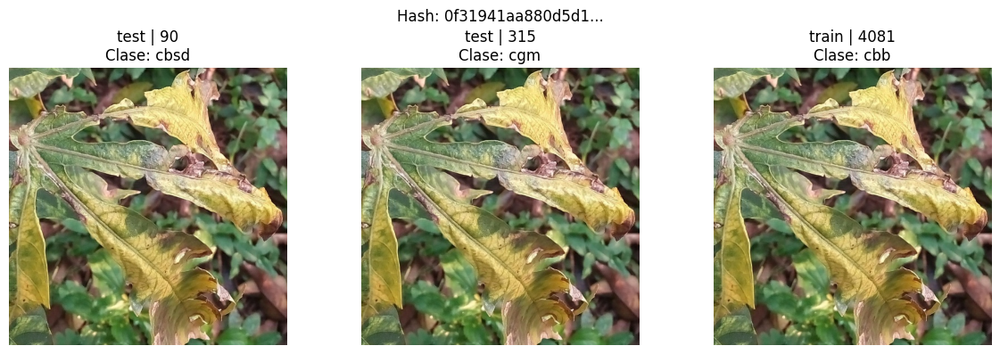

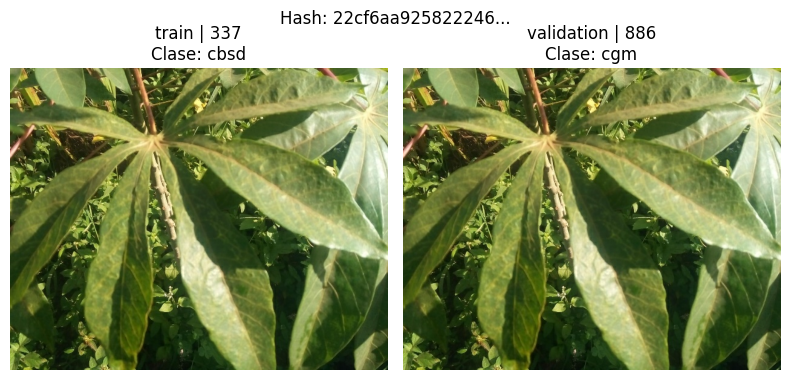

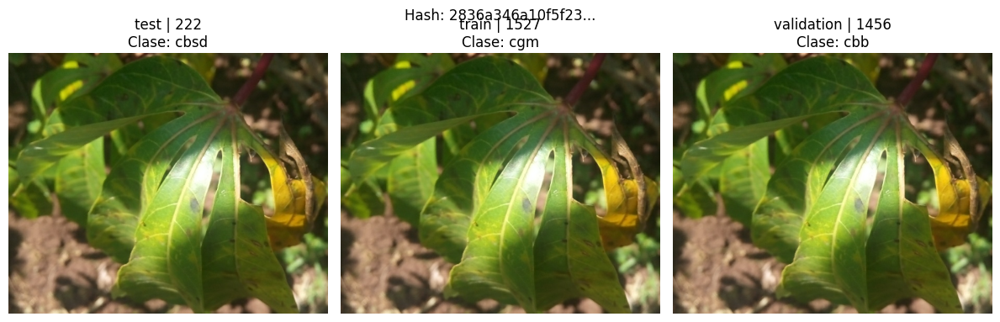

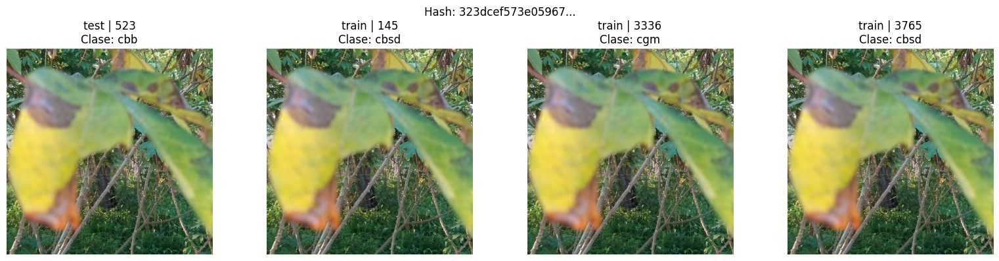

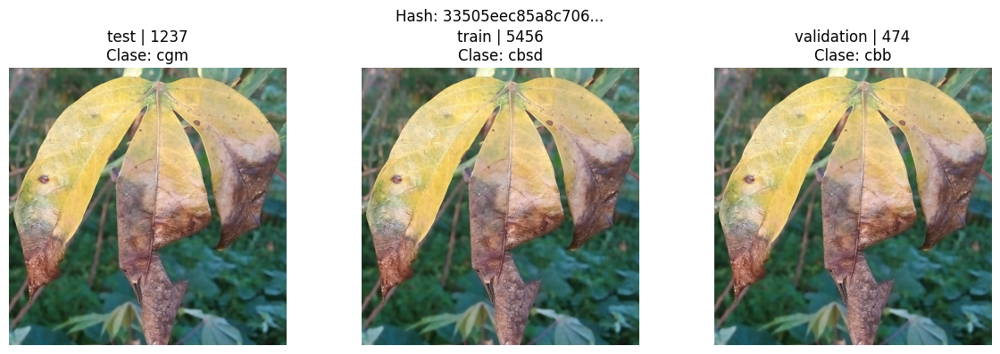

In [16]:
# Seleccionar grupos de duplicados con etiquetas diferentes
resumen_conflictos = duplicados.groupby("hash").agg(
    numero_clases=("clase", "nunique"),
    numero_particiones=("particion", "nunique")
)

hashes_conflictivos = resumen_conflictos[
    resumen_conflictos["numero_clases"] > 1
].index

print("Grupos con etiquetas contradictorias:", len(hashes_conflictivos))

# Visualizar los primeros 5 grupos conflictivos
hashes_a_mostrar = list(hashes_conflictivos)[:5]

grupos_a_mostrar = duplicados[
    duplicados["hash"].isin(hashes_a_mostrar)
]

# Recuperar imágenes mediante el índice registrado
datasets = {
    "train": ds_train,
    "validation": ds_val,
    "test": ds_test
}

# Índices necesarios por partición (solo las imágenes que se van a mostrar)
indices_conflictivos = {
    nombre: set(
        grupos_a_mostrar.loc[
            grupos_a_mostrar["particion"] == nombre,
            "indice"
        ].astype(int)
    )
    for nombre in datasets
}

# Recuperar únicamente las imágenes necesarias
imagenes_conflictivas = {}

for nombre, dataset in datasets.items():
    pendientes = set(indices_conflictivos[nombre])

    if not pendientes:
        continue

    for indice, (imagen, etiqueta) in enumerate(dataset):
        if indice in pendientes:
            imagenes_conflictivas[(nombre, indice)] = imagen.numpy()
            pendientes.discard(indice)

            if not pendientes:
                break

for hash_actual in hashes_a_mostrar:

    grupo = duplicados[
        duplicados["hash"] == hash_actual
    ]

    fig, axes = plt.subplots(
        1, len(grupo),
        figsize=(4 * len(grupo), 4),
        squeeze=False
    )

    for ax, (_, fila) in zip(axes[0], grupo.iterrows()):

        particion = fila["particion"]
        indice = int(fila["indice"])
        clase = fila["clase"]

        imagen = imagenes_conflictivas[(particion, indice)]

        ax.imshow(imagen)
        ax.set_title(f"{particion} | {indice}\nClase: {clase}")
        ax.axis("off")

    plt.suptitle(f"Hash: {hash_actual[:16]}...")
    plt.tight_layout()
    plt.show()

In [17]:
# Resumen de los grupos duplicados
resumen_duplicados = df_hashes.groupby("hash").agg(
    cantidad=("hash", "size"),
    particiones=("particion", "nunique"),
    clases=("clase", "nunique")
).reset_index()

# Grupos con etiquetas contradictorias
conflictos = resumen_duplicados[
    resumen_duplicados["clases"] > 1
]

# Grupos con duplicados pero etiquetas consistentes
consistentes = resumen_duplicados[
    (resumen_duplicados["cantidad"] > 1) &
    (resumen_duplicados["clases"] == 1)
]

print("Grupos con etiquetas contradictorias:", len(conflictos))
print("Registros involucrados en conflictos:",
      df_hashes["hash"].isin(conflictos["hash"]).sum())

print("Grupos duplicados con etiquetas consistentes:",
      len(consistentes))
print("Registros en grupos consistentes:",
      df_hashes["hash"].isin(consistentes["hash"]).sum())

Grupos con etiquetas contradictorias: 18
Registros involucrados en conflictos: 52
Grupos duplicados con etiquetas consistentes: 8
Registros en grupos consistentes: 16


### Limpieza SHA-256: creación de ds_train_limpio, ds_val_limpio y ds_test_limpio

Versión intermedia de los datasets: solo se eliminan los duplicados exactos (SHA-256). La versión definitiva se construye en la sección 9.

In [18]:
# PASO 1: Identificar hashes con etiquetas contradictorias

clases_por_hash = df_hashes.groupby("hash")["clase"].nunique()

hashes_conflictivos = set(
    clases_por_hash[clases_por_hash > 1].index
)

# PASO 2: Crear copia del inventario
df_limpieza = df_hashes.copy()

# Excluir todos los registros de grupos conflictivos
df_limpieza["motivo_exclusion"] = ""

df_limpieza.loc[
    df_limpieza["hash"].isin(hashes_conflictivos),
    "motivo_exclusion"
] = "etiquetas_contradictorias"

# PASO 3: Resolver duplicados consistentes
# Prioridad: test > validation > train

prioridad = {
    "test": 0,
    "validation": 1,
    "train": 2
}

df_limpieza["prioridad"] = (
    df_limpieza["particion"].map(prioridad)
)

candidatos = df_limpieza[
    df_limpieza["motivo_exclusion"] == ""
].sort_values(
    ["prioridad", "indice"]
)

indices_repetidos = candidatos.duplicated(
    subset=["hash"],
    keep="first"
)

df_limpieza.loc[
    candidatos.index[indices_repetidos],
    "motivo_exclusion"
] = "duplicado_consistente"

# PASO 4: Crear manifiestos
df_conservados = df_limpieza[
    df_limpieza["motivo_exclusion"] == ""
].copy()

df_excluidos = df_limpieza[
    df_limpieza["motivo_exclusion"] != ""
].copy()

# PASO 5: Comprobaciones
assert df_conservados["hash"].is_unique
assert len(df_conservados) + len(df_excluidos) == len(df_hashes)

print("Imágenes originales:", len(df_hashes))
print("Imágenes conservadas:", len(df_conservados))
print("Imágenes excluidas:", len(df_excluidos))

print("\nMotivos de exclusión:")
print(df_excluidos["motivo_exclusion"].value_counts())

print("\nDistribución final por partición:")
print(df_conservados["particion"].value_counts())

# PASO 6: Exportar evidencia
import os

os.makedirs("results/eda", exist_ok=True)

df_conservados.drop(
    columns=["prioridad"]
).to_csv("results/eda/manifiesto_conservados.csv", index=False)

df_excluidos.drop(
    columns=["prioridad"]
).to_csv("results/eda/manifiesto_excluidos.csv", index=False)

Imágenes originales: 9430
Imágenes conservadas: 9370
Imágenes excluidas: 60

Motivos de exclusión:
motivo_exclusion
etiquetas_contradictorias    52
duplicado_consistente         8
Name: count, dtype: int64

Distribución final por partición:
particion
train         5616
validation    1879
test          1875
Name: count, dtype: int64


In [19]:
# Obtener índices originales de los registros conservados
indices_train = set(
    df_conservados.loc[
        df_conservados["particion"] == "train", "indice"
    ].astype(int)
)

indices_val = set(
    df_conservados.loc[
        df_conservados["particion"] == "validation", "indice"
    ].astype(int)
)

indices_test = set(
    df_conservados.loc[
        df_conservados["particion"] == "test", "indice"
    ].astype(int)
)

def filtrar_dataset(dataset, indices_validos):
    # Crear máscara booleana según el orden original
    n = int(dataset.cardinality().numpy())

    mascara = tf.constant(
        [i in indices_validos for i in range(n)],
        dtype=tf.bool
    )

    return (
        dataset.enumerate()
        .filter(lambda i, dato: tf.gather(mascara, i))
        .map(lambda i, dato: dato)
    )

ds_train_limpio = filtrar_dataset(ds_train, indices_train)
ds_val_limpio = filtrar_dataset(ds_val, indices_val)
ds_test_limpio = filtrar_dataset(ds_test, indices_test)

print("Train:", ds_train_limpio.cardinality().numpy())
print("Validation:", ds_val_limpio.cardinality().numpy())
print("Test:", ds_test_limpio.cardinality().numpy())

Train: -2
Validation: -2
Test: -2


In [20]:
print("Train:", sum(1 for _ in ds_train_limpio))
print("Validation:", sum(1 for _ in ds_val_limpio))
print("Test:", sum(1 for _ in ds_test_limpio))

Train: 5616
Validation: 1879
Test: 1875


In [21]:
# Verificación de integridad después del filtrado

datasets_limpios = {
    "train": ds_train_limpio,
    "validation": ds_val_limpio,
    "test": ds_test_limpio
}

for nombre, dataset in datasets_limpios.items():

    hashes_reales = [
        obtener_hash(imagen)
        for imagen, etiqueta in dataset
    ]

    hashes_esperados = set(
        df_conservados.loc[
            df_conservados["particion"] == nombre,
            "hash"
        ]
    )

    assert len(hashes_reales) == len(hashes_esperados), (
        f"Cantidad incorrecta en {nombre}"
    )

    assert set(hashes_reales) == hashes_esperados, (
        f"Hashes diferentes en {nombre}"
    )

    print(
        f"{nombre}: {len(hashes_reales)} imágenes verificadas"
    )

print("\nVerificación SHA-256 completada correctamente.")

train: 5616 imágenes verificadas
validation: 1879 imágenes verificadas
test: 1875 imágenes verificadas

Verificación SHA-256 completada correctamente.


## 8. Detección y limpieza de duplicados pHash

In [22]:
%pip install -q ImageHash

In [23]:

import imagehash
from PIL import Image

def obtener_phash(imagen):
    img = Image.fromarray(imagen.numpy())
    return str(imagehash.phash(img))

registros_phash = []

for nombre, dataset in [
    ("train", ds_train),
    ("validation", ds_val),
    ("test", ds_test)
]:
    for i, (imagen, etiqueta) in enumerate(
        tqdm(dataset, desc=f"pHash {nombre}")
    ):
        registros_phash.append({
            "particion": nombre,
            "indice": i,
            "phash": obtener_phash(imagen),
            "clase": class_names[int(etiqueta.numpy())]
        })

df_phash = pd.DataFrame(registros_phash)

print("Imágenes procesadas:", len(df_phash))
print("pHash únicos:", df_phash["phash"].nunique())

pHash train:   0%|          | 0/5656 [00:00<?, ?it/s]

pHash validation:   0%|          | 0/1889 [00:00<?, ?it/s]

pHash test:   0%|          | 0/1885 [00:00<?, ?it/s]

Imágenes procesadas: 9430
pHash únicos: 9381


In [24]:
coincidencias_phash = df_phash[
    df_phash.duplicated("phash", keep=False)
].sort_values("phash")

print(
    "Registros con pHash repetido:",
    len(coincidencias_phash)
)

display(coincidencias_phash.head(30))

Registros con pHash repetido: 82


,particion,indice,phash,clase
2984,train,2984,838b35323c7a077e,cbb
9010,test,1465,838b35323c7a077e,cbsd
638,train,638,838b35323c7a077e,cgm
361,train,361,839c9732bb343636,cbb
2172,train,2172,839c9732bb343636,cbsd
3267,train,3267,839c9732bb343636,cgm
7332,validation,1676,85c33e314dcd4bc6,cmd
8231,test,686,85c33e314dcd4bc6,cmd
5033,train,5033,891ab0a5d68fccdc,cmd
5764,validation,108,891ab0a5d68fccdc,cbb


In [25]:
# Conservar únicamente los registros presentes
# en el manifiesto de limpieza

df_phash_limpio = df_phash.merge(
    df_conservados[["particion", "indice"]],
    on=["particion", "indice"],
    how="inner",
    validate="one_to_one"
)

# Identificar pHash repetidos
coincidencias_phash_limpio = df_phash_limpio[
    df_phash_limpio.duplicated(
        subset=["phash"],
        keep=False
    )
].copy()

# Resumir cada grupo de coincidencias
resumen_phash = (
    coincidencias_phash_limpio
    .groupby("phash")
    .agg(
        registros=("phash", "size"),
        particiones=("particion", "nunique"),
        clases=("clase", "nunique")
    )
)

print("Imágenes analizadas:", len(df_phash_limpio))

print(
    "Grupos con pHash repetido:",
    len(resumen_phash)
)

print(
    "Registros involucrados:",
    len(coincidencias_phash_limpio)
)

print(
    "Grupos entre distintas particiones:",
    (resumen_phash["particiones"] > 1).sum()
)

print(
    "Grupos con etiquetas diferentes:",
    (resumen_phash["clases"] > 1).sum()
)

# Comprobaciones
assert len(df_phash_limpio) == 9370
assert not df_phash_limpio.duplicated(
    ["particion", "indice"]
).any()

Imágenes analizadas: 9370
Grupos con pHash repetido: 7
Registros involucrados: 14
Grupos entre distintas particiones: 4
Grupos con etiquetas diferentes: 2


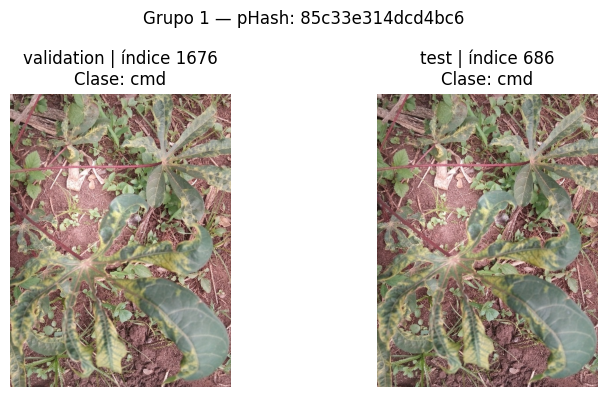

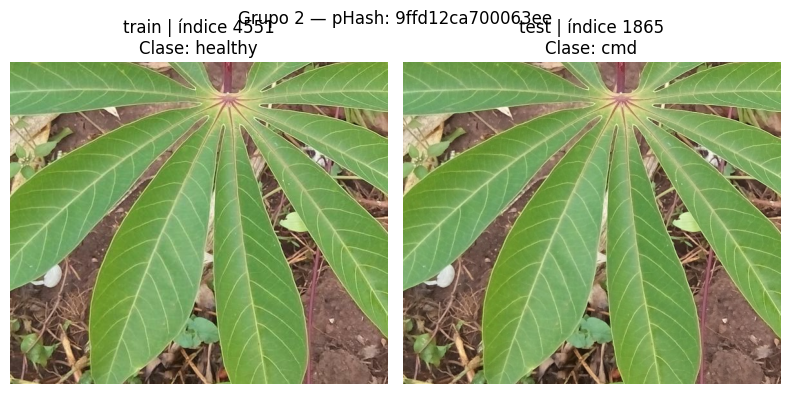

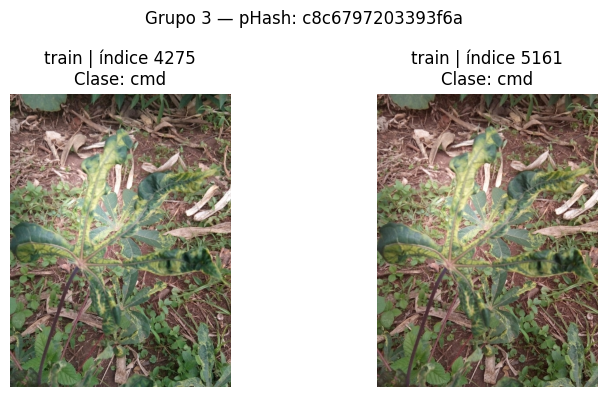

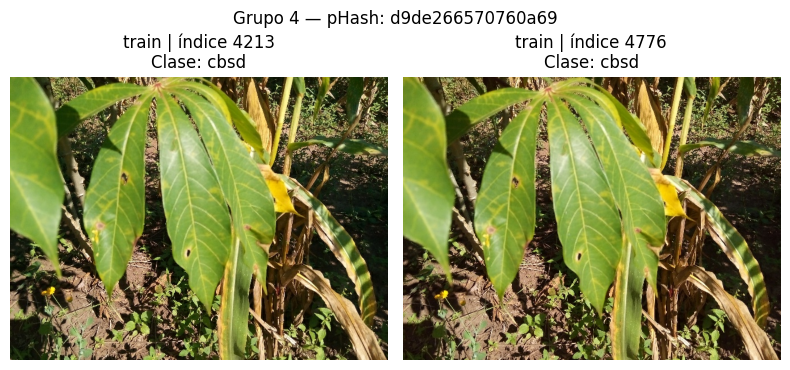

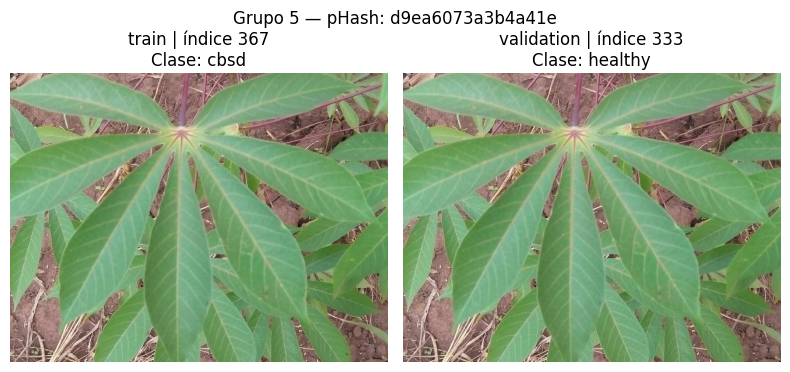

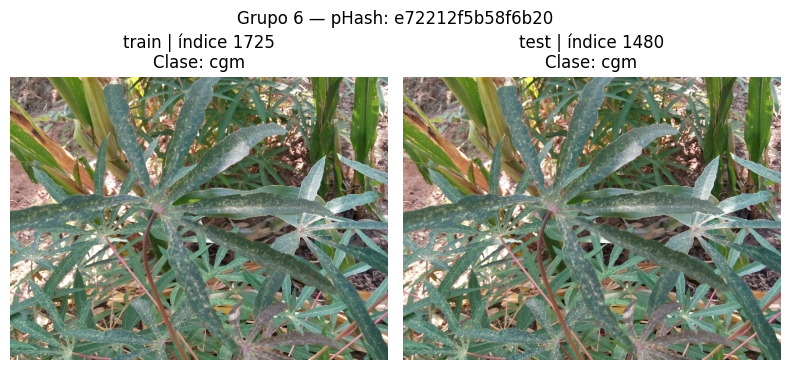

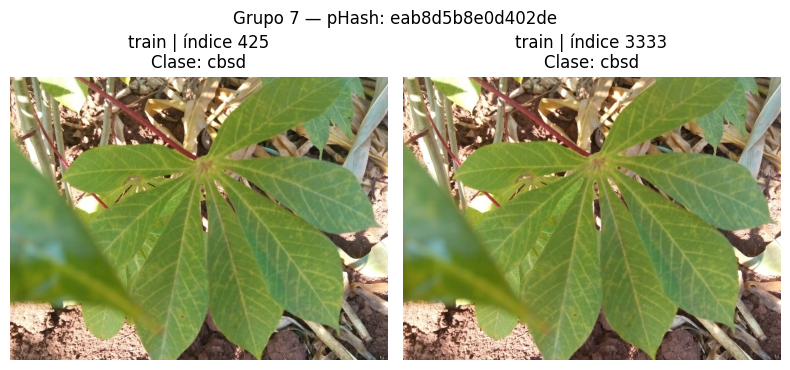

In [26]:

# Obtener los índices originales de los registros sospechosos
indices_por_particion = {
    nombre: set(
        coincidencias_phash_limpio.loc[
            coincidencias_phash_limpio["particion"] == nombre,
            "indice"
        ].astype(int)
    )
    for nombre in ["train", "validation", "test"]
}

# Recuperar únicamente las imágenes necesarias
imagenes_sospechosas = {}

for nombre, dataset in {
    "train": ds_train,
    "validation": ds_val,
    "test": ds_test
}.items():

    indices = indices_por_particion[nombre]

    for indice, (imagen, etiqueta) in enumerate(dataset):
        if indice in indices:
            imagenes_sospechosas[(nombre, indice)] = imagen.numpy()

# Visualizar cada grupo de pHash repetido
for numero, (hash_actual, grupo) in enumerate(
    coincidencias_phash_limpio.groupby("phash"),
    start=1
):
    cantidad = len(grupo)

    fig, axes = plt.subplots(
        1, cantidad,
        figsize=(4 * cantidad, 4),
        squeeze=False
    )

    for ax, (_, fila) in zip(axes[0], grupo.iterrows()):

        particion = fila["particion"]
        indice = int(fila["indice"])

        imagen = imagenes_sospechosas[(particion, indice)]

        ax.imshow(imagen)
        ax.set_title(
            f"{particion} | índice {indice}\n"
            f"Clase: {fila['clase']}"
        )
        ax.axis("off")

    plt.suptitle(
        f"Grupo {numero} — pHash: {hash_actual}"
    )

    plt.tight_layout()
    plt.show()

In [27]:
# Crear una copia del manifiesto depurado por SHA-256
df_final = df_conservados.copy()

# Añadir la columna 'phash' cruzando con df_phash usando 'particion' e 'indice'
df_final = df_final.merge(
    df_phash[["particion", "indice", "phash"]],
    on=["particion", "indice"],
    how="left"
)


In [28]:
# Reiniciar las marcas de exclusión pHash
df_final["motivo_exclusion_phash"] = ""

# 1. Excluir grupos con etiquetas contradictorias
hashes_conflictivos_phash = set(
    resumen_phash.loc[
        resumen_phash["clases"] > 1
    ].index
)

df_final.loc[
    df_final["phash"].isin(hashes_conflictivos_phash),
    "motivo_exclusion_phash"
] = "phash_etiquetas_contradictorias"

# 2. Conservar una sola imagen por pHash consistente
prioridad = {
    "test": 0,
    "validation": 1,
    "train": 2
}

df_final["prioridad"] = df_final["particion"].map(prioridad)

candidatos = df_final[
    df_final["motivo_exclusion_phash"] == ""
].sort_values(["prioridad", "indice"])

repetidos = candidatos.duplicated(
    subset=["phash"],
    keep="first"
)

df_final.loc[
    candidatos.index[repetidos],
    "motivo_exclusion_phash"
] = "phash_duplicado_consistente"

# 3. Crear manifiestos finales
df_conservados_final = df_final[
    df_final["motivo_exclusion_phash"] == ""
].copy()

df_excluidos_phash = df_final[
    df_final["motivo_exclusion_phash"] != ""
].copy()

# 4. Verificar resultados
assert df_conservados_final["hash"].is_unique
assert df_conservados_final["phash"].is_unique

print("Imágenes originales:", 9430)
print("Imágenes después de SHA-256:", len(df_final))
print("Imágenes excluidas por pHash:", len(df_excluidos_phash))
print("Imágenes finales:", len(df_conservados_final))

print("\nMotivos de exclusión pHash:")
print(df_excluidos_phash["motivo_exclusion_phash"].value_counts())

print("\nDistribución final por partición:")
print(df_conservados_final["particion"].value_counts())

# 5. Guardar resultados
df_conservados_final.to_csv(
    "results/eda/manifiesto_final_conservados.csv",
    index=False
)

df_excluidos_phash.to_csv(
    "results/eda/exclusiones_phash.csv",
    index=False
)

Imágenes originales: 9430
Imágenes después de SHA-256: 9370
Imágenes excluidas por pHash: 9
Imágenes finales: 9361

Motivos de exclusión pHash:
motivo_exclusion_phash
phash_duplicado_consistente        5
phash_etiquetas_contradictorias    4
Name: count, dtype: int64

Distribución final por partición:
particion
train         5610
validation    1877
test          1874
Name: count, dtype: int64


## 9. Construcción y verificación de datasets definitivos

Versión definitiva (SHA-256 + pHash): ds_train_final, ds_val_final y ds_test_final. Sustituye a los datasets intermedios ds_*_limpio de la sección 7.

In [29]:
# Crear datasets definitivos a partir del manifiesto final

def crear_dataset_final(dataset_original, particion):
    indices_validos = set(
        df_conservados_final.loc[
            df_conservados_final["particion"] == particion,
            "indice"
        ].astype(int)
    )

    cantidad_original = int(
        dataset_original.cardinality().numpy()
    )

    mascara = tf.constant(
        [
            i in indices_validos
            for i in range(cantidad_original)
        ],
        dtype=tf.bool
    )

    dataset_final = (
        dataset_original
        .enumerate()
        .filter(lambda i, dato: tf.gather(mascara, i))
        .map(lambda i, dato: dato)
    )

    return dataset_final


ds_train_final = crear_dataset_final(
    ds_train, "train"
)

ds_val_final = crear_dataset_final(
    ds_val, "validation"
)

ds_test_final = crear_dataset_final(
    ds_test, "test"
)

# Verificar cantidades reales
n_train = sum(1 for _ in ds_train_final)
n_val = sum(1 for _ in ds_val_final)
n_test = sum(1 for _ in ds_test_final)

print("Train:", n_train)
print("Validation:", n_val)
print("Test:", n_test)
print("Total:", n_train + n_val + n_test)

assert n_train == 5610
assert n_val == 1877
assert n_test == 1874

print("\nDatasets definitivos creados correctamente.")

Train: 5610
Validation: 1877
Test: 1874
Total: 9361

Datasets definitivos creados correctamente.


## 10. Inspección de calidad visual

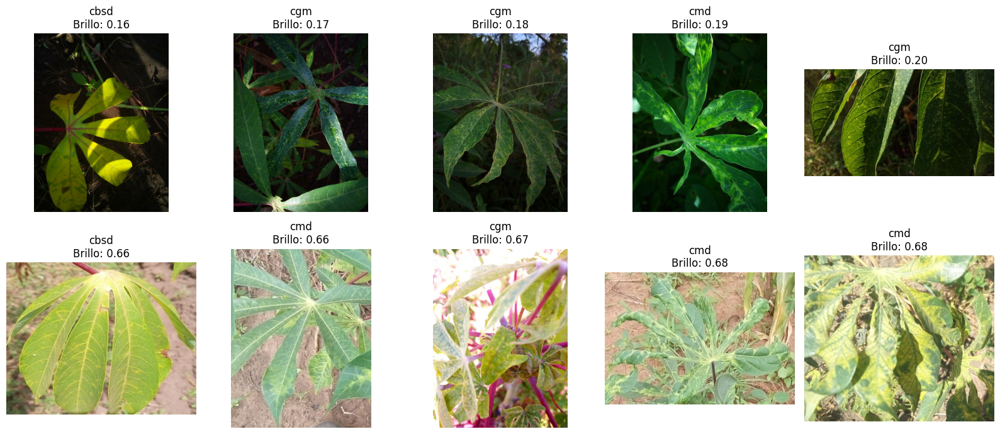

In [30]:
# Seleccionar las 5 imágenes más oscuras
# y las 5 más brillantes de entrenamiento

indices = df_estadisticas.sort_values("brillo")

seleccion = list(indices.head(5).index) + list(
    indices.tail(5).index
)

seleccion_set = set(seleccion)
imagenes_seleccionadas = {}

for i, (imagen, etiqueta) in enumerate(ds_train):
    if i in seleccion_set:
        imagenes_seleccionadas[i] = (
            imagen.numpy(),
            int(etiqueta.numpy())
        )

    if len(imagenes_seleccionadas) == len(seleccion_set):
        break

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for posicion, indice in enumerate(seleccion):
    fila, columna = divmod(posicion, 5)
    imagen, etiqueta = imagenes_seleccionadas[indice]

    axes[fila, columna].imshow(imagen)
    axes[fila, columna].set_title(
        f"{class_names[etiqueta]}\n"
        f"Brillo: {df_estadisticas.loc[indice, 'brillo']:.2f}"
    )
    axes[fila, columna].axis("off")

plt.tight_layout()
plt.show()

## 11. Distribución final de clases

In [31]:
# Distribución final de clases después de la limpieza

distribucion_final = pd.crosstab(
    df_conservados_final["clase"],
    df_conservados_final["particion"]
)

# Ordenar columnas
distribucion_final = distribucion_final[
    ["train", "validation", "test"]
]

# Agregar total por clase
distribucion_final["total"] = (
    distribucion_final["train"]
    + distribucion_final["validation"]
    + distribucion_final["test"]
)

# Porcentaje sobre el dataset final
distribucion_final["porcentaje"] = (
    distribucion_final["total"] / 9361 * 100
).round(2)

print("Distribución final de clases:")
display(distribucion_final)

# Verificar totales
assert distribucion_final["train"].sum() == 5610
assert distribucion_final["validation"].sum() == 1877
assert distribucion_final["test"].sum() == 1874
assert distribucion_final["total"].sum() == 9361

print("\nDistribución verificada correctamente.")

# Exportar resultados
distribucion_final.to_csv(
    "results/eda/distribucion_clases_final.csv"
)

Distribución final de clases:


particion,train,validation,test,total,porcentaje
clase,,,,,
cbb,455,151,154,760,8.12
cbsd,1426,479,477,2382,25.45
cgm,762,257,253,1272,13.59
cmd,2652,885,885,4422,47.24
healthy,315,105,105,525,5.61



Distribución verificada correctamente.


## 12. Exportación de resultados

In [32]:
os.makedirs("results/eda", exist_ok=True)

df_dimensiones.to_csv(
    "results/eda/dimensiones.csv",
    index=False
)

df_estadisticas.to_csv(
    "results/eda/estadisticas_color.csv",
    index=False
)

df_hashes.to_csv(
    "results/eda/hashes_exactos.csv",
    index=False
)

df_phash.to_csv(
    "results/eda/hashes_perceptuales.csv",
    index=False
)

df_conteos = pd.DataFrame({
    "clase": class_names,
    "cantidad": conteos,
    "porcentaje": conteos / conteos.sum() * 100
})

df_conteos.to_csv(
    "results/eda/distribucion_clases.csv",
    index=False
)

print("Resultados del EDA exportados correctamente")

Resultados del EDA exportados correctamente
